# Step 3 — One picture → 4096 numbers (VGG-16)

**Goal:** take an image crop and turn it into a 4096-length feature vector (its "fingerprint").

**The idea:** VGG-16 is a CNN. Its convolution layers detect patterns (edges → parts → whole objects); its fully-connected layers squeeze the result into **4096 numbers** — the `fc7` feature. We read it out **after the ReLU**, so every value is `>= 0` (this matches what we saw in the author's real `.npz`).

Before feeding a crop to VGG we must **preprocess** it: resize to 224×224, scale to 0–1, normalize with ImageNet mean/std.

⚠️ First run downloads VGG-16 (~528 MB). Run cells with **Shift+Enter**.

## 1. Load a frame and make two example crops
We'll compare the **whole frame** (slot 0) against a **small center crop** (pretend-object) to see that different pictures give different fingerprints.

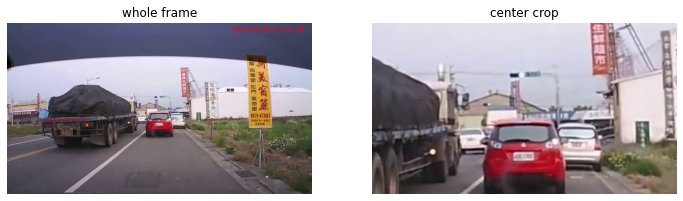

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

VIDEO_PATH = "../Dataset/videos/test/Accident/000456.mp4"
FRAME_INDEX = 50

cap = cv2.VideoCapture(VIDEO_PATH)
frames = []
while True:
    ok, f = cap.read()
    if not ok:
        break
    frames.append(f)
cap.release()

frame_rgb = cv2.cvtColor(frames[FRAME_INDEX], cv2.COLOR_BGR2RGB)
H, W, _ = frame_rgb.shape

whole_frame = frame_rgb                                  # slot-0 style crop
center_crop = frame_rgb[H//3:2*H//3, W//3:2*W//3]         # a small region

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(whole_frame); axes[0].set_title("whole frame"); axes[0].axis("off")
axes[1].imshow(center_crop); axes[1].set_title("center crop"); axes[1].axis("off")
plt.show()

## 2. Build the VGG-16 fc7 feature extractor
VGG's classifier head is: `[Linear, ReLU, Dropout, Linear, ReLU, Dropout, Linear]`.
Taking the first **5** layers stops right after the **second ReLU** → that is `fc7`, post-ReLU, 4096-d.

In [2]:
from torchvision.models import vgg16
try:
    from torchvision.models import VGG16_Weights
    vgg = vgg16(weights=VGG16_Weights.IMAGENET1K_V1)
except Exception:
    vgg = vgg16(pretrained=True)
vgg.eval()

features   = vgg.features                                    # conv layers
avgpool    = vgg.avgpool                                      # fixed-size pooling
fc7        = nn.Sequential(*list(vgg.classifier.children())[:5])  # up to 2nd ReLU
print("VGG-16 ready. fc7 head:")
print(fc7)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\niles/.cache\torch\hub\checkpoints\vgg16-397923af.pth


A Jupyter Widget

VGG-16 ready. fc7 head:
Sequential(
  (0): Linear(in_features=25088, out_features=4096, bias=True)
  (1): ReLU(inplace=True)
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=4096, out_features=4096, bias=True)
  (4): ReLU(inplace=True)
)


## 3. The preprocessing + extraction function
`crop (RGB) -> resize 224 -> 0..1 -> normalize -> VGG -> 4096 numbers`

In [3]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMAGENET_STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def to_feature(crop_rgb):
    resized = cv2.resize(crop_rgb, (224, 224))              # VGG input size
    x = torch.from_numpy(resized).float() / 255.0            # 0..1
    x = x.permute(2, 0, 1).unsqueeze(0)                      # (1, 3, 224, 224)
    x = (x - IMAGENET_MEAN) / IMAGENET_STD                   # normalize
    with torch.no_grad():
        x = features(x)
        x = avgpool(x)
        x = torch.flatten(x, 1)
        x = fc7(x)                                           # (1, 4096)
    return x.squeeze(0).numpy()                              # (4096,)

## 4. Turn each crop into 4096 numbers and inspect

In [4]:
vec_frame  = to_feature(whole_frame)
vec_center = to_feature(center_crop)

print("whole-frame feature:", vec_frame.shape, vec_frame.dtype)
print("  min / max / mean :", round(float(vec_frame.min()),3),
      round(float(vec_frame.max()),3), round(float(vec_frame.mean()),3))
print("  all values >= 0 ? ", bool((vec_frame >= 0).all()), "(because of ReLU)")
print("  first 10 numbers :", np.round(vec_frame[:10], 2))
print()
print("center-crop feature:", vec_center.shape)

# How similar are the two fingerprints? (1.0 = identical direction, 0 = unrelated)
cos = float(np.dot(vec_frame, vec_center) /
            (np.linalg.norm(vec_frame) * np.linalg.norm(vec_center) + 1e-8))
print("\ncosine similarity between the two crops:", round(cos, 3),
      "-> different pictures -> different fingerprints")

whole-frame feature: (4096,) float32
  min / max / mean : 0.0 3.076 0.255
  all values >= 0 ?  True (because of ReLU)
  first 10 numbers : [0.   0.27 0.   0.95 0.   0.   0.3  0.4  1.7  0.43]

center-crop feature: (4096,)

cosine similarity between the two crops: 0.467 -> different pictures -> different fingerprints


## 5. See the fingerprint
A feature vector is just 4096 numbers. Here it is as a bar-ish plot — notice it is **sparse** (many zeros) and non-negative, exactly like the real data.

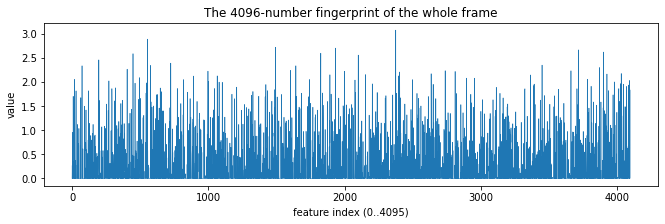

fraction of values that are exactly 0: 0.638


In [5]:
plt.figure(figsize=(11, 3))
plt.plot(vec_frame, linewidth=0.6)
plt.title("The 4096-number fingerprint of the whole frame")
plt.xlabel("feature index (0..4095)"); plt.ylabel("value")
plt.show()

print("fraction of values that are exactly 0:",
      round(float((vec_frame == 0).mean()), 3))

## What to take away
1. **Any image crop → VGG-16 → 4096 numbers.** That's the "feature" / fingerprint.
2. We read `fc7` **after ReLU**, so values are `>= 0` and **sparse** — matching the author's `.npz`.
3. Preprocessing matters: resize 224×224, scale 0–1, ImageNet-normalize.
4. Different pictures give different fingerprints (low cosine similarity).

Now we have both tools: **detector (boxes)** + **VGG (fingerprints)**.

Next: **Step 4 — one whole frame → its (20, 4096) slots** (whole frame + each detected object).